In [1]:
# Cell 1: Install Playwright in Colab
!pip install playwright nest_asyncio
!playwright install --with-deps chromium

Installing dependencies...
Hit:1 https://cloud.r-project.org/bin/linux/ubuntu noble-cran40/ InRelease
Hit:2 https://cli.github.com/packages stable InRelease
Hit:3 http://security.ubuntu.com/ubuntu noble-security InRelease
Hit:4 https://r2u.stat.illinois.edu/ubuntu noble InRelease
Hit:5 http://archive.ubuntu.com/ubuntu noble InRelease
Hit:6 http://archive.ubuntu.com/ubuntu noble-updates InRelease
Hit:7 http://archive.ubuntu.com/ubuntu noble-backports InRelease
Hit:8 https://ppa.launchpadcontent.net/deadsnakes/ppa/ubuntu noble InRelease
Reading package lists... Done
W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
libasound2t64 is already the newest version (1.2.11-1ubuntu0.3).
libatk-bridge2.0-0t64 is already the newest version (2.52.0-1build1).
libatk1.

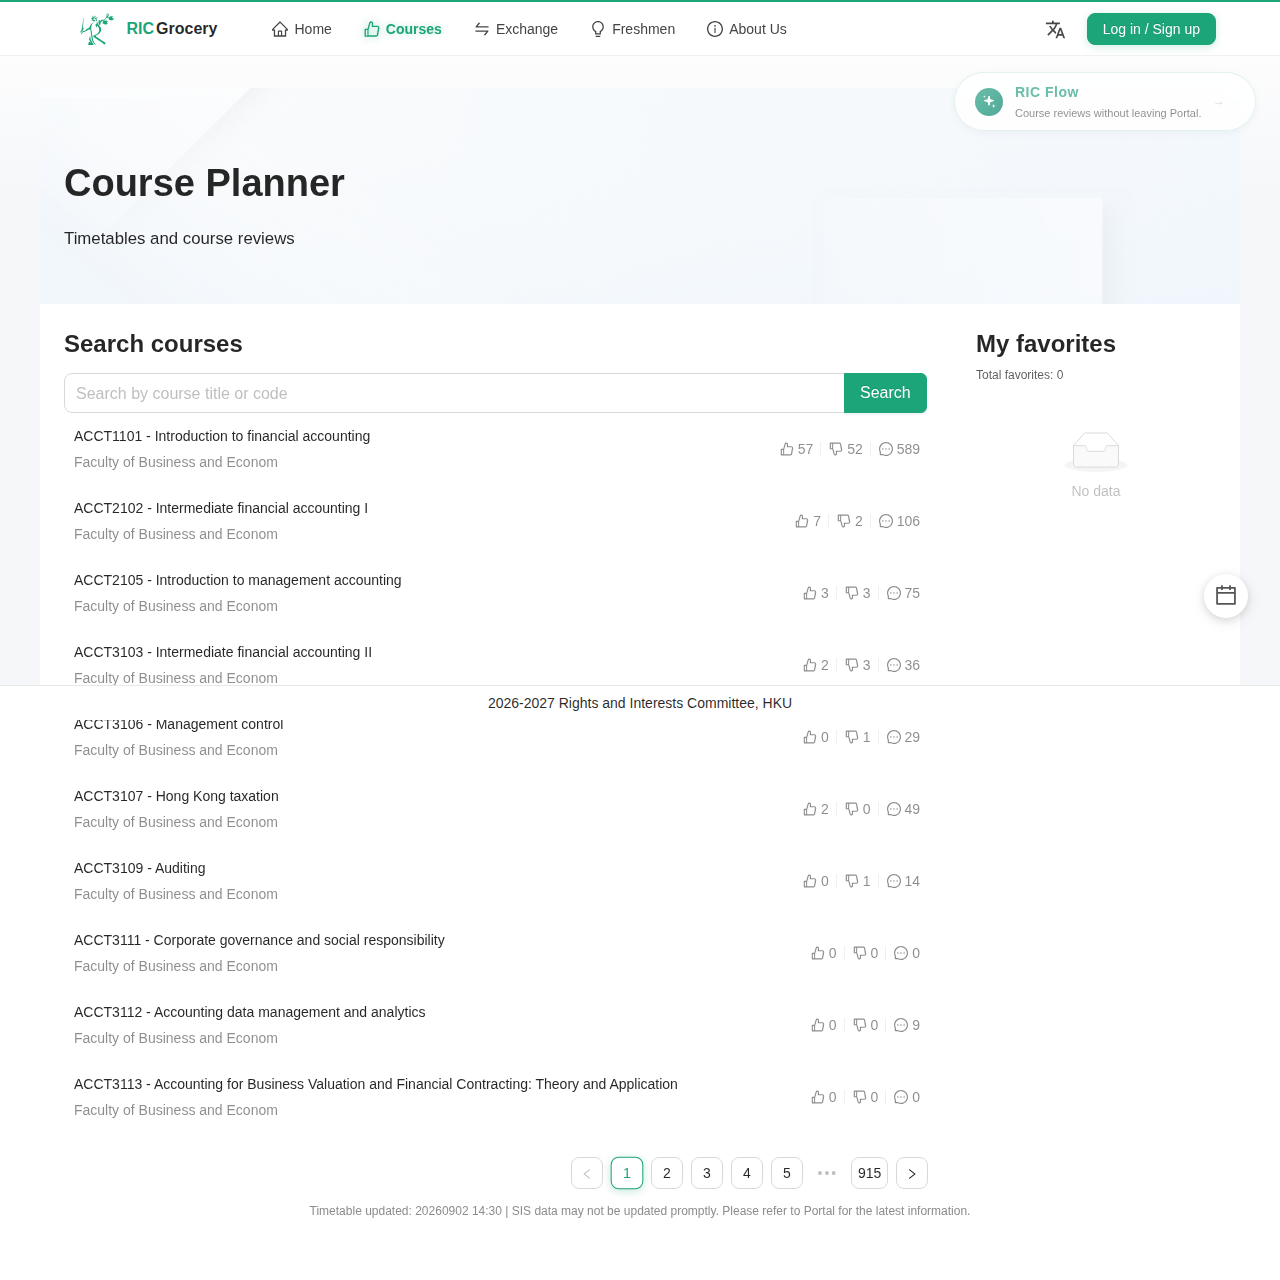

In [2]:
# Cell 2: Initialize Browser & Login to RIC
import asyncio
import nest_asyncio
nest_asyncio.apply()

from playwright.async_api import async_playwright
from IPython.display import Image, display
import json

playwright = await async_playwright().start()
browser = await playwright.chromium.launch(headless=True)
context = await browser.new_context(
    user_agent="Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/120.0.0.0 Safari/537.36"
)
page = await context.new_page()

# Go to RIC courses page
await page.goto("https://richku.com/courses")
await page.wait_for_timeout(3000)

# Take a screenshot to see if login is required
img = await page.screenshot(full_page=True)
display(Image(img))

In [3]:
# List all visible buttons and links on the current page
buttons = await page.locator("button, a").all_inner_texts()
print("Buttons/Links on page:", [b.strip() for b in buttons if b.strip()])

# List all input boxes on the current page
inputs = await page.locator("input").all()
for i, inp in enumerate(inputs):
    print(f"Input #{i}: type='{await inp.get_attribute('type')}', placeholder='{await inp.get_attribute('placeholder')}'")

Buttons/Links on page: ['RICGrocery', 'Home', 'Courses', 'Exchange', 'Freshmen', 'About Us', 'Log in / Sign up', 'Log in / Sign up', 'Search', 'ACCT1101 - Introduction to financial accounting\nFaculty of Business and Econom\n 57\n 52\n 589', 'ACCT2102 - Intermediate financial accounting I\nFaculty of Business and Econom\n 7\n 2\n 106', 'ACCT2105 - Introduction to management accounting\nFaculty of Business and Econom\n 3\n 3\n 75', 'ACCT3103 - Intermediate financial accounting II\nFaculty of Business and Econom\n 2\n 3\n 36', 'ACCT3106 - Management control\nFaculty of Business and Econom\n 0\n 1\n 29', 'ACCT3107 - Hong Kong taxation\nFaculty of Business and Econom\n 2\n 0\n 49', 'ACCT3109 - Auditing\nFaculty of Business and Econom\n 0\n 1\n 14', 'ACCT3111 - Corporate governance and social responsibility\nFaculty of Business and Econom\n 0\n 0\n 0', 'ACCT3112 - Accounting data management and analytics\nFaculty of Business and Econom\n 0\n 0\n 9', 'ACCT3113 - Accounting for Business Valua

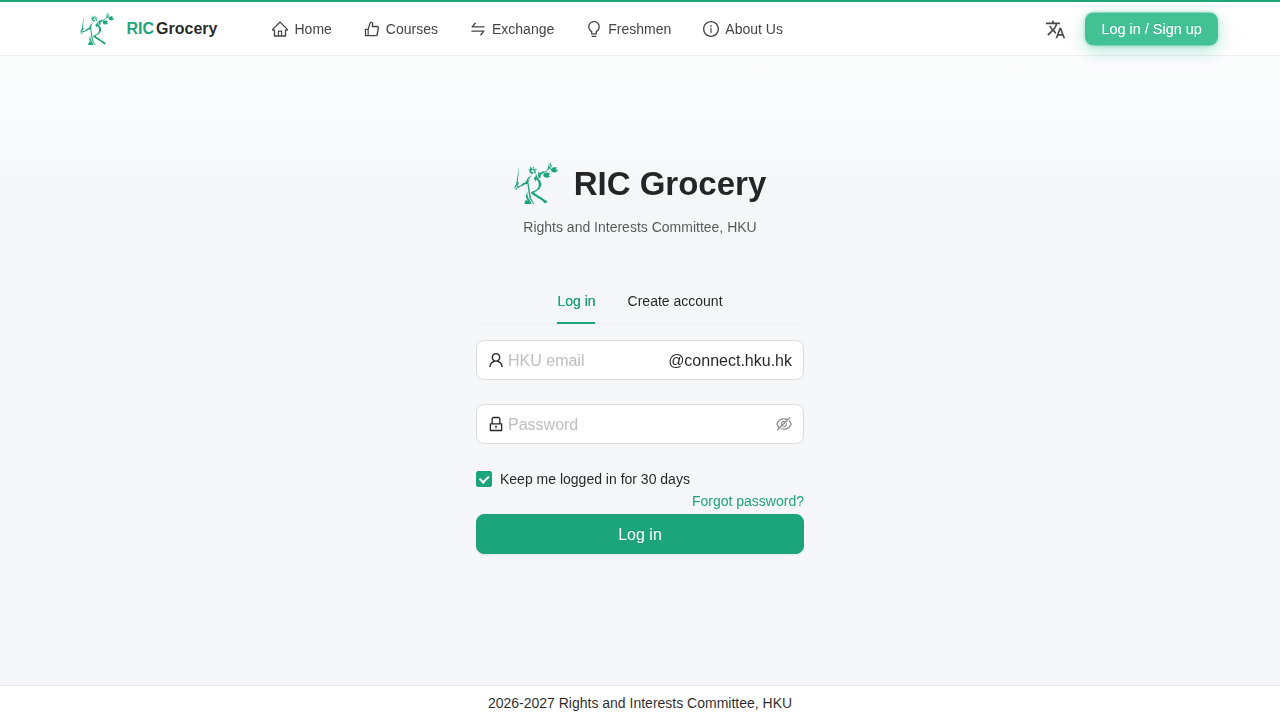

In [4]:
# Option 1: Click the button that says Login or Sign in (case-insensitive)
await page.get_by_text("Log in / Sign up", exact=False).first.click()

# (If Option 1 gives an error, comment it out and try Option 2:await page.goto("https://richku.com/login"))

await page.wait_for_timeout(3000)

# Take a screenshot to see where it took us!
img = await page.screenshot(full_page=True)
display(Image(img))

In [ ]:
# input confidential information
UID = input("enter UID: ")
password = input("enter password: ")

# Fill the email box
await page.locator('input[type="email"], input[name*="email"], input[placeholder*="email" i]').first.fill(UID)

# Fill the password box (if there is one)
await page.locator('input[type="password"]').first.fill(password)

# Click the submit/login button
await page.locator('input[type="password"]').first.press("Enter")

await page.wait_for_timeout(4000)
display(Image(await page.screenshot(full_page=True)))

In [7]:
import json

# 1. Check if ric-info.json was saved on disk earlier
try:
    with open("ric-info.json", "r") as f:
        saved_data = json.load(f)
    for code, info in saved_data.items():
        for a in info.get("api_json", []):
            print("Saved API URL:", a["url"])
            print("Preview:", str(a["data"])[:300], "\n")
except FileNotFoundError:
    print("No ric-info.json on disk yet, testing live on page...")

# 2. Catch live JSON APIs when we search and click CCCH9001
live_apis = []
async def catch_api(response):
    try:
        if "json" in response.headers.get("content-type", "") and response.status == 200:
            data = await response.json()
            live_apis.append({"url": response.url, "data": data})
    except:
        pass

page.on("response", catch_api)

await page.goto("https://richku.com/courses")
await page.wait_for_timeout(3000)

search_input = page.locator('input[placeholder*="Search" i], input[type="text"], input[type="search"]').first
search_btn = page.get_by_text("Search", exact=True).first

for test_code in ["CCST9003", "CCCH9001"]:
    live_apis.clear()
    # Fill search box and trigger click inside JS (never blocked by overlays!)
    await search_input.fill(test_code, force=True)
    await search_btn.evaluate("el => el.click()")
    await page.wait_for_timeout(2000)

    body_now = await page.locator("body").inner_text()
    print(f"Did {test_code} appear in search list? ->", f"{test_code} -" in body_now)

    # Click the course card using JS click too!
    card = page.get_by_text(f"{test_code} -", exact=False).first
    if await card.count() > 0:
        await card.evaluate("el => el.click()")
        await page.wait_for_timeout(2500)
        body_after = await page.locator("body").inner_text()
        print(f"Did Course details: {test_code} open? ->", f"Course details: {test_code}" in body_after)
        for a in live_apis:
            print("  Caught API URL:", a["url"])
            print("  API Data Preview:", str(a["data"])[:250])

No ric-info.json on disk yet, testing live on page...
Did CCST9003 appear in search list? -> True
Did Course details: CCST9003 open? -> True
  Caught API URL: https://api.richku.com/v1/courses?search=CCST9003&current=1&page_size=10&order=asc&sort=code
  API Data Preview: {'success': True, 'status': 200, 'message': '200 OK', 'showType': 0, 'data': {'list': [{'code': 'CCST9003', 'title': 'Everyday Computing and the Internet', 'offer_dept': 'University Central', 'requirement': 'Your enrollment must comply with the <a hr
  Caught API URL: https://api.richku.com/v1/courses/CCST9003
  API Data Preview: {'success': True, 'status': 200, 'message': '200 OK', 'showType': 0, 'data': {'code': 'CCST9003', 'title': 'Everyday Computing and the Internet', 'offer_dept': 'University Central', 'requirement': 'Your enrollment must comply with the <a href=https:/
  Caught API URL: https://api.richku.com/v1/favorites/courses?current=1&page_size=10&order=asc&sort=course_code
  API Data Preview: {'success': T

In [10]:
import json

# 1. Load your 334 CC course codes (excluding CCAI)
course_codes = []
for filename in ["cc-site-info.json", "enrol-info.json", "sis-info.json"]:
    try:
        with open(filename, "r") as f:
            course_codes.extend(list(json.load(f).keys()))
    except FileNotFoundError:
        pass

cc_courses = sorted(list(set([
    c.strip().upper() for c in course_codes
    if c.strip().upper().startswith("CC") and not c.strip().upper().startswith("CCAI")
])))
print(f"Total unique CC courses to scrape: {len(cc_courses)}")

# Load any previously saved progress
try:
    with open("ric-info.json", "r") as f:
        ric_data = json.load(f)
except FileNotFoundError:
    ric_data = {}

# 2. Listener that automatically catches the clean JSON from api.richku.com!
current_course_json = {"search": None, "details": None, "reviews": None}

async def catch_ric_api(response):
    url = response.url
    if "api.richku.com/v1/courses" in url and response.status == 200:
        try:
            res_json = await response.json()
            if not res_json.get("success"):
                return
            if "/reviews" in url:
                current_course_json["reviews"] = res_json.get("data")
            elif "?search=" in url:
                current_course_json["search"] = res_json.get("data")
            else:
                current_course_json["details"] = res_json.get("data")
        except:
            pass

page.on("response", catch_ric_api)

# 3. Go to /courses once
await page.goto("https://richku.com/courses")
await page.wait_for_timeout(3000)

search_input = page.locator('input[placeholder*="Search" i], input[type="text"], input[type="search"]').first
search_btn = page.get_by_text("Search", exact=True).first

for i, code in enumerate(cc_courses):
    # Skip if already scraped cleanly
    if code in ric_data and ric_data[code].get("course_info"):
        print(f"[{i+1}/{len(cc_courses)}] {code} already saved, skipping.")
        continue

    print(f"[{i+1}/{len(cc_courses)}] Scraping {code}...", end=" ")
    current_course_json["search"] = None
    current_course_json["details"] = None
    current_course_json["reviews"] = None

    try:
        # Step A: Fill search bar and trigger Search button via JS click (never blocked by drawer!)
        await search_input.fill(code, force=True)
        await search_btn.evaluate("el => el.click()")

        # Wait up to 3 seconds for the search API response to arrive
        for _ in range(15):
            await page.wait_for_timeout(200)
            if current_course_json["search"] is not None:
                break

        # Check if the course exists in the search API response
        search_list = (current_course_json["search"] or {}).get("list") or []
        matched_summary = next((item for item in search_list if item.get("code") == code), None)

        if not matched_summary:
            print("Not listed on RIC.")
            continue

        # Step B: Click the course card via JS click to trigger details & reviews APIs
        await page.wait_for_timeout(300)
        card = page.get_by_text(f"{code} -", exact=False).first
        if await card.count() > 0:
            await card.evaluate("el => el.click()")
            # Wait up to 3.5 seconds for both details and reviews JSON APIs to arrive
            for _ in range(18):
                await page.wait_for_timeout(200)
                if current_course_json["details"] is not None and current_course_json["reviews"] is not None:
                    break

        # Grab visible text too just in case
        body_text = await page.locator("body").inner_text()
        split_idx = body_text.find("Course details:")
        details_text = body_text[split_idx:] if split_idx != -1 else ""

        reviews_data = current_course_json["reviews"] or {}
        reviews_list = reviews_data.get("list") or []

        ric_data[code] = {
            "search_summary": matched_summary,
            "course_info": current_course_json["details"] or matched_summary,
            "reviews": reviews_list,
            "reviews_total": reviews_data.get("total", len(reviews_list)),
            "course_details_text": details_text
        }

        likes = matched_summary.get("liked_count", 0)
        dislikes = matched_summary.get("disliked_count", 0)
        rev_cnt = matched_summary.get("reviewed_count", 0)
        print(f"OK! (Likes: {likes}, Dislikes: {dislikes}, Total Reviews: {rev_cnt}, Fetched: {len(reviews_list)})")

        # Save every 10 courses
        if (i + 1) % 10 == 0:
            with open("ric-info.json", "w") as f:
                json.dump(ric_data, f, indent=4)

    except Exception as e:
        print(f"Error: {e}")
        await page.goto("https://richku.com/courses")
        await page.wait_for_timeout(2500)

with open("ric-info.json", "w") as f:
    json.dump(ric_data, f, indent=4)

print(f"\n🎉 FINISHED! Saved {len(ric_data)} CC courses to 'ric-info.json'!")

Total unique CC courses to scrape: 334
[1/334] Scraping CCCH5006... OK! (Likes: 0, Dislikes: 0, Total Reviews: 0, Fetched: 0)
[2/334] Scraping CCCH5017... OK! (Likes: 0, Dislikes: 0, Total Reviews: 12, Fetched: 10)
[3/334] Scraping CCCH5039... OK! (Likes: 0, Dislikes: 0, Total Reviews: 5, Fetched: 5)
[4/334] Scraping CCCH5044... OK! (Likes: 0, Dislikes: 1, Total Reviews: 4, Fetched: 4)
[5/334] Scraping CCCH5054... OK! (Likes: 2, Dislikes: 3, Total Reviews: 8, Fetched: 8)
[6/334] Scraping CCCH5057... OK! (Likes: 0, Dislikes: 0, Total Reviews: 5, Fetched: 5)
[7/334] Scraping CCCH6001... OK! (Likes: 0, Dislikes: 0, Total Reviews: 0, Fetched: 0)
[8/334] Scraping CCCH9001... OK! (Likes: 21, Dislikes: 8, Total Reviews: 139, Fetched: 10)
[9/334] Scraping CCCH9002... OK! (Likes: 6, Dislikes: 7, Total Reviews: 22, Fetched: 10)
[10/334] Scraping CCCH9003... OK! (Likes: 5, Dislikes: 1, Total Reviews: 6, Fetched: 6)
[11/334] Scraping CCCH9004... OK! (Likes: 3, Dislikes: 2, Total Reviews: 14, Fetch